In [4]:
%load_ext autoreload
%autoreload 2
import os, sys
import numpy as np
import pandas as pd
from itertools import combinations
from pathlib import Path
from scipy.optimize import brentq
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm

In [5]:
# Output directory for plots
plots_dir = os.path.join(os.getcwd(), "plots")
os.makedirs(plots_dir, exist_ok=True)

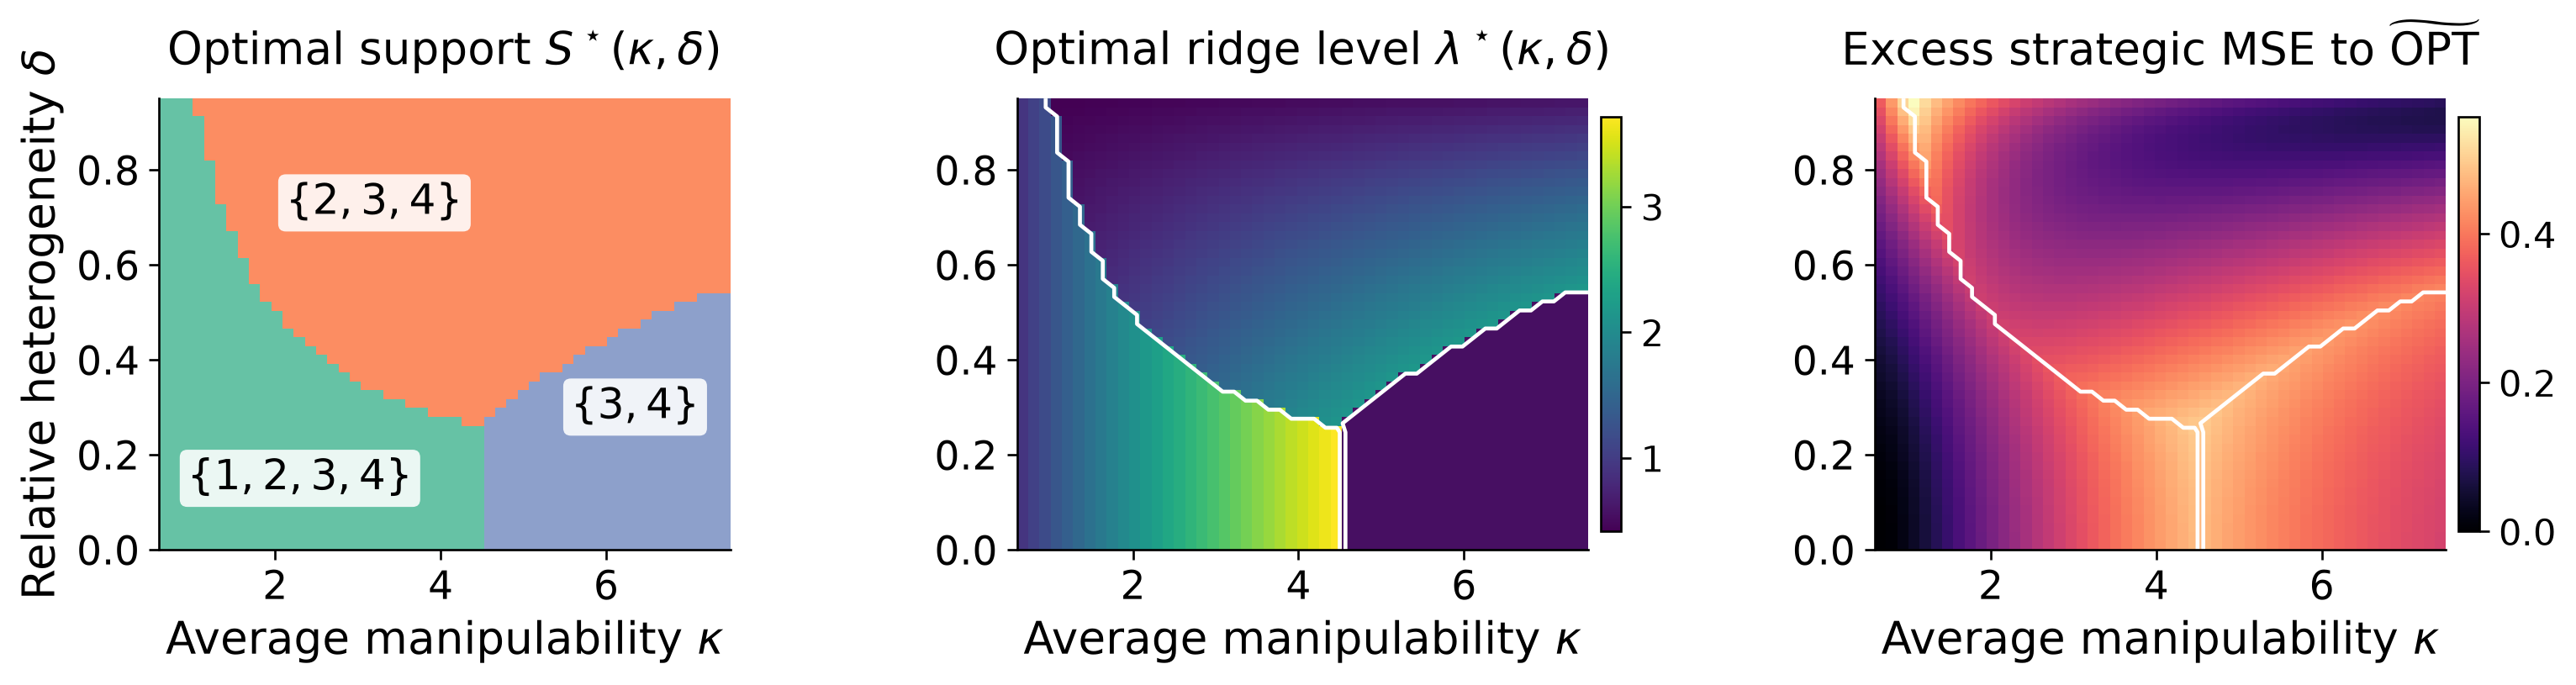

In [6]:
# Problem setup
d = 4
Sigma = np.eye(d)
theta_star = np.array([1.2, 1.2, 1.0, 0.9], float)

kappa_grid = np.linspace(0.6, 7.5, 51)
delta_grid = np.linspace(0.0, 0.95, 51)

support_order = [
    (0, 1, 2, 3),
    (1, 2, 3),
    (2, 3),
]
support_labels = {
    (0, 1, 2, 3): r'$\left\{1,2,3,4\right\}$',
    (1, 2, 3): r'$\left\{2,3,4\right\}$',
    (2, 3): r'$\left\{3,4\right\}$',
}
support_colors = ['#66c2a5', '#fc8d62', '#8da0cb']

def support_label_plain(S):
    return '{}' if len(S) == 0 else '{' + ','.join(str(i + 1) for i in S) + '}'

def make_K_diag(kappa, delta):
    return np.array([
        kappa * (1.0 + delta),
        kappa * (1.0 - delta),
        0.6,
        0.6,
    ], float)

def mse_strat(theta, Kdiag):
    diff = theta - theta_star
    q = np.sum(Kdiag * theta**2)
    return float(diff @ diff + q**2)

def theta_or(S, lam):
    th = np.zeros(d)
    if len(S) == 0:
        return th
    shrink = 1.0 / (1.0 + lam)
    th[list(S)] = shrink * theta_star[list(S)]
    return th

def ridge_best(S, Kdiag, lam_max=20.0):
    S = tuple(S)
    if len(S) == 0:
        th = np.zeros(d)
        return mse_strat(th, Kdiag), 0.0

    retained = theta_star[list(S)]
    k_ret = Kdiag[list(S)]

    c = float(np.sum(retained**2))
    q = float(np.sum(k_ret * retained**2)) ** 2

    coeff = [4.0 * q, 0.0, 2.0 * c, -2.0 * c]
    roots = np.roots(coeff)

    t_min = 1.0 / (1.0 + lam_max)
    candidates = [1.0, t_min]

    for r in roots:
        if abs(r.imag) < 1e-10:
            t = float(r.real)
            if t_min - 1e-10 <= t <= 1.0 + 1e-10:
                candidates.append(min(1.0, max(t_min, t)))

    best_val = None
    best_lam = None
    for t in candidates:
        lam = 1.0 / t - 1.0
        th = theta_or(S, lam)
        val = mse_strat(th, Kdiag)
        if best_val is None or val < best_val - 1e-12:
            best_val = float(val)
            best_lam = float(lam)

    return best_val, best_lam

def support_oracle_value(S, Kdiag):
    S = tuple(S)
    if len(S) == 0:
        return float(np.sum(theta_star**2))

    keep = np.zeros(d, dtype=bool)
    keep[list(S)] = True

    omitted = theta_star[~keep]
    retained = theta_star[keep]
    k_ret = Kdiag[keep]
    omitted_cost = float(np.sum(omitted**2))

    def g(Q):
        return np.sum(k_ret * retained**2 / (1.0 + 2.0 * k_ret * Q)**2) - Q

    hi = max(1.0, np.sum(k_ret * retained**2))
    while g(hi) > 0:
        hi *= 2.0
        if hi > 1e8:
            break

    Q_star = brentq(g, 0.0, hi, xtol=1e-12, rtol=1e-10, maxiter=200)
    theta_oracle = retained / (1.0 + 2.0 * k_ret * Q_star)

    pred = omitted_cost + np.sum((theta_oracle - retained)**2)
    return float(pred + Q_star**2)

# Data generation
rows = []
all_supports = [S for k in range(d + 1) for S in combinations(range(d), k)]

for delta in delta_grid:
    for kappa in kappa_grid:
        Kdiag = make_K_diag(kappa, delta)
        tilde_opt = support_oracle_value((0, 1, 2, 3), Kdiag)

        best_support = None
        best_lambda = None
        best_risk = None

        for S in all_supports:
            val, lam = ridge_best(S, Kdiag)
            if best_risk is None or val < best_risk - 1e-12:
                best_support = tuple(S)
                best_lambda = float(lam)
                best_risk = float(val)

        opt_S = support_oracle_value(best_support, Kdiag)

        rows.append({
            'kappa': float(kappa),
            'delta': float(delta),
            'support': best_support,
            'support_plain': support_label_plain(best_support),
            'lambda_star': float(best_lambda),
            'mse_subset_ridge': float(best_risk),
            'tilde_opt': float(tilde_opt),
            'tilde_opt_S': float(opt_S),
            'support_restriction_cost': float(opt_S - tilde_opt),
            'ridge_gap': float(best_risk - opt_S),
            'total_gap': float(best_risk - tilde_opt),
        })

df = pd.DataFrame(rows)

# Plotting setup
appearing_supports = [S for S in support_order if S in set(df['support'])]
support_to_code = {S: i for i, S in enumerate(appearing_supports)}
df['support_code'] = df['support'].apply(lambda S: support_to_code[tuple(S)])

kappa_vals = np.sort(df['kappa'].unique())
delta_vals = np.sort(df['delta'].unique())
extent = [kappa_vals.min(), kappa_vals.max(), delta_vals.min(), delta_vals.max()]

support_grid = df.pivot(index='delta', columns='kappa', values='support_code').loc[delta_vals, kappa_vals].values
lambda_grid = df.pivot(index='delta', columns='kappa', values='lambda_star').loc[delta_vals, kappa_vals].values
total_gap_grid = df.pivot(index='delta', columns='kappa', values='total_gap').loc[delta_vals, kappa_vals].values

plt.rcParams.update({
    'font.size': 15.0,
    'axes.labelsize': 16.0,
    'axes.titlesize': 16.0,
    'xtick.labelsize': 14.0,
    'ytick.labelsize': 14.0,
    'legend.fontsize': 14.0,
    'figure.dpi': 240,
    'savefig.dpi': 300,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})

def add_region_labels(ax):
    labels = [
        (2.30, 0.15, support_labels[(0, 1, 2, 3)]),
        (3.20, 0.73, support_labels[(1, 2, 3)]),
        (6.35, 0.30, support_labels[(2, 3)]),
    ]
    for x, y, txt in labels:
        ax.text(
            x, y, txt,
            ha='center', va='center', fontsize=15.0,
            bbox=dict(facecolor='white', edgecolor='none', alpha=0.88,
                      boxstyle='round,pad=0.18')
        )

def make_three_panel_figure(fig, axes):
    ax1, ax2, ax3 = axes

    cmap_support = ListedColormap(support_colors[:len(appearing_supports)])
    norm_support = BoundaryNorm(np.arange(-0.5, len(appearing_supports) + 0.5, 1.0), cmap_support.N)

    im1 = ax1.imshow(
        support_grid, origin='lower', aspect='auto', extent=extent,
        cmap=cmap_support, norm=norm_support, interpolation='nearest'
    )
    ax1.set_title(r'Optimal support $S^\star(\kappa,\delta)$', loc='center', pad=12)
    add_region_labels(ax1)
    cbar1 = fig.colorbar(im1, ax=ax1, shrink=0.92, pad=0.018)
    cbar1.ax.set_visible(False)

    im2 = ax2.imshow(
        lambda_grid, origin='lower', aspect='auto', extent=extent,
        cmap='viridis', interpolation='nearest'
    )
    ax2.contour(
        kappa_vals, delta_vals, support_grid,
        levels=np.arange(0.5, len(appearing_supports) - 0.49, 1.0),
        colors='white', linewidths=1.4
    )
    ax2.set_title(r'Optimal ridge level $\lambda^\star(\kappa,\delta)$', loc='center', pad=12)
    cbar2 = fig.colorbar(im2, ax=ax2, shrink=0.92, pad=0.018)
    cbar2.ax.tick_params(labelsize=13.0)

    im3 = ax3.imshow(
        total_gap_grid, origin='lower', aspect='auto', extent=extent,
        cmap='magma', interpolation='nearest'
    )
    ax3.contour(
        kappa_vals, delta_vals, support_grid,
        levels=np.arange(0.5, len(appearing_supports) - 0.49, 1.0),
        colors='white', linewidths=1.4
    )
    ax3.set_title(r'Excess strategic MSE to $\widetilde{\mathrm{OPT}}$', loc='center', pad=12)
    cbar3 = fig.colorbar(im3, ax=ax3, shrink=0.92, pad=0.018)
    cbar3.ax.tick_params(labelsize=13.0)

    ax1.set_ylabel(r'Relative heterogeneity $\delta$')
    for ax in axes:
        ax.set_xlabel(r'Average manipulability $\kappa$')

fig, axes = plt.subplots(1, 3, figsize=(12.8, 3.55), constrained_layout=False)
make_three_panel_figure(fig, axes)
fig.subplots_adjust(left=0.055, right=0.985, top=0.85, bottom=0.22, wspace=0.25)

fig.savefig(os.path.join(plots_dir, 'homogeneous_costs_phase.pdf'), bbox_inches='tight')
fig.savefig(os.path.join(plots_dir, 'homogeneous_costs_phase.png'), bbox_inches='tight')

plt.show()